# 03. 시군구 전세사기 위험등급 산출

**SEMESH for Android · 데이터 분석 3단계**

방법 설명: `docs/03_위험등급_방법론.md` · 코드: `03_risk_grade.py`

```
① 지표 계산      피해율(과거 피해) + 보증사고율(최근 사고)   ← 분모는 둘 다 전세 계약 수
② 작은 표본 보정  표본이 작은 지역의 값을 전국 평균 쪽으로 당김 (경험적 베이즈)
③ 종합 점수      두 지표를 0~100 백분위로 바꿔 0.5 : 0.5 평균
④ 등급          상위 20% 고위험 · 다음 30% 주의 · 나머지 50% 안전
⑤ 검증          민감도 분석, 지자체 데이터 비교, 두 지표 비교
```

## 0. 준비

In [1]:
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

BASE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
P = BASE / "data" / "processed"

# 03_risk_grade.py 안의 함수를 불러와서 노트북에서도 똑같이 쓴다 (파일 이름이 숫자로 시작해서 import 대신 이 방법 사용)
spec = importlib.util.spec_from_file_location("risk", BASE / "03_risk_grade.py")
risk = importlib.util.module_from_spec(spec); spec.loader.exec_module(risk)

df = pd.read_csv(P / "region_merged.csv", dtype={"지역코드": str})
df["이름"] = df["시도"] + " " + df["시군구"]
print(df.shape)
df[["이름", "피해주택_누적", "사고건수", "사고율", "전세계약수"]].head()

(255, 19)


,이름,피해주택_누적,사고건수,사고율,전세계약수
0,서울 종로구,6,6,2.0,4739
1,서울 중구,51,4,1.5,5019
2,서울 용산구,0,1,0.1,13004
3,서울 성동구,3,1,0.1,7768
4,서울 광진구,22,11,1.8,16927


## ① 지표 계산

| | 피해율 | 보증사고율 |
|---|---|---|
| 분자 | 피해주택 (2023.7~2025.12 누적) | 보증사고 (2026.6~8 월평균) |
| 분모 | 전세 계약 (같은 30개월 누적) | 전세 계약 (월평균 = 누적 ÷ 30) |
| 단위 | 전세 1,000건당 | 월 전세 1,000건당 |

In [2]:
df["월평균_전세계약"] = df["전세계약수"] / 30
df["피해율_원값"] = df["피해주택_누적"] / df["전세계약수"] * 1000
df["보증사고율_원값"] = df["사고건수"] / df["월평균_전세계약"] * 1000

print("전세 계약 0건 지역:", (df["전세계약수"] == 0).sum(), "곳")
print("전세 계약 수 — 최소", int(df["전세계약수"].min()), "/ 중앙값", int(df["전세계약수"].median()),
      "/ 최대", int(df["전세계약수"].max()))

전세 계약 0건 지역: 0 곳
전세 계약 수 — 최소 12 / 중앙값 971 / 최대 24303


### 건수 순위 vs 비율 순위
지난 학기처럼 **건수**로 줄 세운 것과 이번에 **비율**로 줄 세운 것을 나란히 본다.

In [3]:
by_count = df.sort_values("피해주택_누적", ascending=False).head(10)[["이름", "피해주택_누적", "전세계약수"]]
by_rate = df.sort_values("피해율_원값", ascending=False).head(10)[["이름", "피해주택_누적", "전세계약수", "피해율_원값"]]
display(by_count.reset_index(drop=True).rename(columns={"이름": "건수 기준 상위"}))
display(by_rate.round(2).reset_index(drop=True).rename(columns={"이름": "비율(원값) 기준 상위"}))

,건수 기준 상위,피해주택_누적,전세계약수
0,서울 강서구,390,21957
1,인천 미추홀구,241,6648
2,서울 금천구,195,9734
3,서울 구로구,148,9437
4,서울 관악구,143,14515
5,경기 화성동탄구,121,7750
6,인천 부평구,112,7578
7,서울 은평구,91,14423
8,경기 부천원미구,90,6074
9,서울 양천구,83,10522


,비율(원값) 기준 상위,피해주택_누적,전세계약수,피해율_원값
0,전남 광양시,52,205,253.66
1,충북 보은군,3,29,103.45
2,전남 순천시,37,419,88.31
3,전남 나주시,44,510,86.27
4,전남 곡성군,3,58,51.72
5,세종 세종시,78,1735,44.96
6,인천 미추홀구,241,6648,36.25
7,서울 금천구,195,9734,20.03
8,전남 화순군,1,50,20.00
9,경북 청도군,1,50,20.00


**관찰** — 비율 원값 상위에는 피해 몇 건뿐인 **계약 수가 아주 적은 지역**이 섞여 들어온다.
이것이 ②에서 보정이 필요한 이유다.

## ② 작은 표본 보정 (경험적 베이즈)

```
보정 비율 = (사건 수 + m × 전국 평균) ÷ (계약 수 + m)
```
`m`(가상 계약 수)을 데이터에서 계산하는 과정을 한 줄씩 따라가 본다. (피해율 기준)

In [4]:
x = df["피해주택_누적"].astype(float)      # 사건 수
n = df["전세계약수"].astype(float)          # 계약 수 (노출량)
has = n > 0

p = x[has].sum() / n[has].sum()                                   # 1) 전국 평균
rate = x[has] / n[has]
s2 = (n[has] * (rate - p) ** 2).sum() / n[has].sum()              # 2) 계약 수로 가중한 분산 (전체 퍼짐)
chance = p / n[has].mean()                                        # 3) 표본이 작아서 생기는 우연한 퍼짐
A = s2 - chance                                                   #    → 진짜 지역 차이
m = p / A                                                         # 4) 가상 계약 수

print(f"1) 전국 평균 p        = {p*1000:.3f} (1,000건당)")
print(f"2) 전체 퍼짐 s2       = {s2:.3e}")
print(f"3) 우연한 퍼짐        = {chance:.3e}")
print(f"   진짜 지역 차이 A   = {A:.3e}  (전체 퍼짐의 {A/s2:.0%})")
print(f"4) 가상 계약 수 m     = {m:,.0f}건")

1) 전국 평균 p        = 5.976 (1,000건당)
2) 전체 퍼짐 s2       = 6.065e-05
3) 우연한 퍼짐        = 2.073e-06
   진짜 지역 차이 A   = 5.858e-05  (전체 퍼짐의 97%)
4) 가상 계약 수 m     = 102건


- **진짜 지역 차이가 전체 퍼짐의 대부분**이면, 지역 간 차이가 우연이 아니라는 뜻이다.
- 계약이 `m`건보다 훨씬 많은 지역은 거의 자기 값 그대로, 훨씬 적은 지역은 평균 쪽으로 크게 당겨진다.

이제 `03_risk_grade.py`의 함수로 두 지표를 모두 보정한다 (위 계산과 같은 식).

In [5]:
res, params = risk.compute(df)
for name, (pp, mm) in params.items():
    print(f"{name}: 전국 평균 {pp:.3f} (1,000건당), m = {mm:,.0f}")

피해율: 전국 평균 5.976 (1,000건당), m = 102
보증사고율: 전국 평균 33.184 (1,000건당), m = 22


### 보정 전후 비교: 계약 수가 적은 지역이 어떻게 바뀌나

In [6]:
cols = ["이름", "전세계약수", "피해주택_누적", "피해율_원값", "피해율_보정"]
before = res.sort_values("피해율_원값", ascending=False).head(10)[cols]
before.round(2).reset_index(drop=True)

,이름,전세계약수,피해주택_누적,피해율_원값,피해율_보정
0,전남 광양시,205,52,253.66,171.36
1,충북 보은군,29,3,103.45,27.55
2,전남 순천시,419,37,88.31,72.19
3,전남 나주시,510,44,86.27,72.89
4,전남 곡성군,58,3,51.72,22.56
5,세종 세종시,1735,78,44.96,42.79
6,인천 미추홀구,6648,241,36.25,35.79
7,서울 금천구,9734,195,20.03,19.89
8,전남 화순군,50,1,20.00,10.59
9,경북 청도군,50,1,20.00,10.59


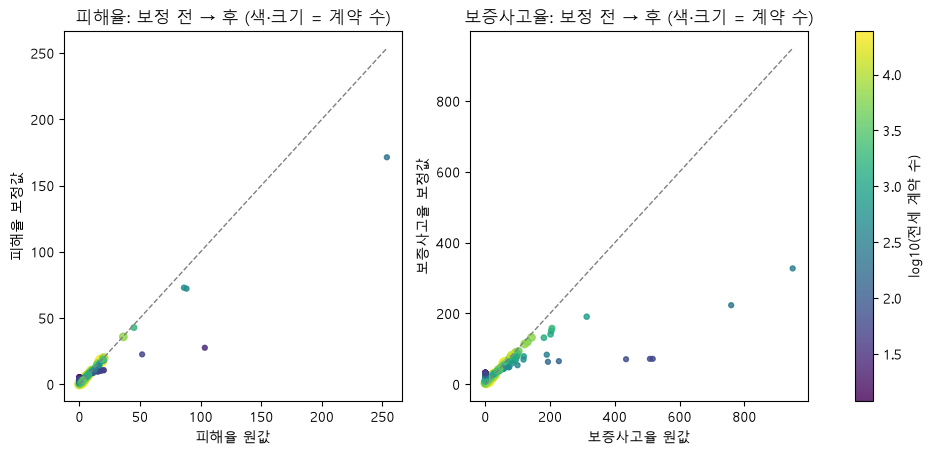

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (raw, eb, title) in zip(axes, [("피해율_원값", "피해율_보정", "피해율"),
                                        ("보증사고율_원값", "보증사고율_보정", "보증사고율")]):
    d = res[res["전세계약수"] > 0]
    sc = ax.scatter(d[raw], d[eb], s=12 + 60 * d["전세계약수"] / d["전세계약수"].max(),
                    c=np.log10(d["전세계약수"]), cmap="viridis", alpha=0.8)
    lim = max(d[raw].max(), d[eb].max())
    ax.plot([0, lim], [0, lim], "--", color="gray", lw=1)
    ax.set_xlabel(f"{title} 원값"); ax.set_ylabel(f"{title} 보정값")
    ax.set_title(f"{title}: 보정 전 → 후 (색·크기 = 계약 수)")
fig.colorbar(sc, ax=axes, label="log10(전세 계약 수)")
plt.show()

**읽는 법** — 점선 위에 있으면 보정해도 그대로인 지역(계약 수가 많은 큰 점),
점선 아래로 크게 떨어진 점은 **계약 수가 적어서 원값이 과장됐던 지역**(작은 점)이다.

## ③ 종합 점수와 ④ 등급
두 보정값을 0~100 백분위로 바꿔 반반 평균 → 상위 20% 고위험, 다음 30% 주의, 나머지 안전.

In [8]:
print(res["등급"].value_counts().reindex(["고위험", "주의", "안전"]))
res.sort_values("순위").head(20)[["순위", "이름", "피해율_보정", "보증사고율_보정",
                                  "피해율_백분위", "보증사고율_백분위", "종합점수", "등급"]].round(1).reset_index(drop=True)

등급
고위험     51
주의      76
안전     128
Name: count, dtype: int64


,순위,이름,피해율_보정,보증사고율_보정,피해율_백분위,보증사고율_백분위,종합점수,등급
0,1,인천 미추홀구,35.8,113.7,98.4,96.5,97.5,고위험
1,2,경남 거제시,11.0,327.3,91.8,100.0,95.9,고위험
2,3,부산 금정구,18.8,78.5,96.5,92.9,94.7,고위험
3,3,인천 부평구,14.7,90.0,93.7,95.7,94.7,고위험
4,5,경기 화성동탄구,15.5,73.9,94.5,91.8,93.1,고위험
5,6,서울 강서구,17.7,59.3,95.7,85.1,90.4,고위험
6,7,인천 계양구,14.6,67.9,93.3,87.3,90.3,고위험
7,8,광주 동구,10.0,77.1,87.8,92.5,90.2,고위험
8,8,경북 포항북구,7.9,190.9,81.2,99.2,90.2,고위험
9,10,인천 남동구,10.7,69.5,91.0,89.0,90.0,고위험


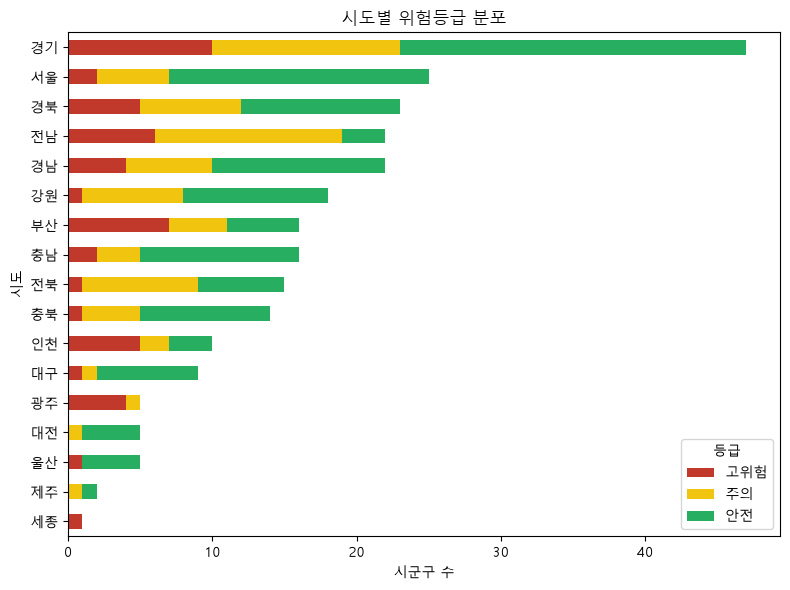

In [9]:
by_sido = pd.crosstab(res["시도"], res["등급"])[["고위험", "주의", "안전"]]
by_sido = by_sido.loc[by_sido.sum(axis=1).sort_values(ascending=False).index]
ax = by_sido.plot(kind="barh", stacked=True, figsize=(8, 6), color=["#C0392B", "#F1C40F", "#27AE60"])
ax.invert_yaxis(); ax.set_xlabel("시군구 수"); ax.set_title("시도별 위험등급 분포")
plt.tight_layout(); plt.show()

서울만 고위험인 게 아니라 **인천·경기·지방 대도시에도 고위험 시군구가 분포**하는지 확인한다.

## ⑤ 검증

### ⑤-1 민감도 분석: 가중치를 바꿔도 결과가 비슷한가

In [10]:
risk.sensitivity(df)

,가중치(피해:사고),고위험 겹침,종합점수 순위상관
0,0.7:0.3,46/51,0.936
1,0.3:0.7,41/51,0.932


### ⑤-2 다른 출처와 비교: 지자체 피해자 결정 현황
서울시(자치구별)·경기도(시군별)가 따로 공개한 **전세사기 피해 결정 건수(2023~2025)**와 비교한다.
HUG 데이터(경공매 신청자만 포함)가 전체 피해 분포를 잘 대표하는지 보는 것이다.
- **스피어만 순위상관**: 두 순위가 얼마나 비슷한지 (-1 ~ 1). 1에 가까울수록 같다.

In [11]:
V = BASE / "data" / "raw" / "validation"
seoul_v = pd.read_csv(V / "서울_자치구별_전세사기_발생건수_2023-2025.csv", encoding="cp949", thousands=",")
seoul_v = seoul_v[seoul_v["구분"] != "총합계"].copy()
for c in ["2023년", "2024년", "2025년"]:
    seoul_v[c] = pd.to_numeric(seoul_v[c].astype(str).str.replace(",", "").str.strip())
seoul_v["지자체_피해"] = seoul_v[["2023년", "2024년", "2025년"]].sum(axis=1)

s = res[res["시도"] == "서울"].merge(seoul_v[["구분", "지자체_피해"]], left_on="시군구", right_on="구분")
s["지자체_피해율"] = s["지자체_피해"] / s["전세계약수"] * 1000
print(f"서울 {len(s)}개 구")
print(f"  건수끼리:  HUG 피해주택 vs 지자체 피해  ρ = {s['피해주택_누적'].corr(s['지자체_피해'], method='spearman'):.3f}")
print(f"  비율끼리:  HUG 보정 피해율 vs 지자체 피해율  ρ = {s['피해율_보정'].corr(s['지자체_피해율'], method='spearman'):.3f}")
print(f"  종합점수 vs 지자체 피해율  ρ = {s['종합점수'].corr(s['지자체_피해율'], method='spearman'):.3f}")

서울 25개 구
  건수끼리:  HUG 피해주택 vs 지자체 피해  ρ = 0.853
  비율끼리:  HUG 보정 피해율 vs 지자체 피해율  ρ = 0.730
  종합점수 vs 지자체 피해율  ρ = 0.684


In [12]:
gg_v = pd.read_csv(V / "경기_시군별_전세사기_발생건수_2023-2025.csv", encoding="cp949")
gg_v = gg_v.groupby("시군명")["발생건수"].sum().rename("지자체_피해")

# 경기 지자체 자료는 '수원시' 단위, 우리 표는 '수원장안구' 단위 → 구를 시로 묶어서 비교
g = res[res["시도"] == "경기"].copy()
def to_city(name):
    for city in ["수원", "성남", "안양", "부천", "안산", "고양", "용인", "화성"]:
        if name.startswith(city) and name.endswith("구"):
            return city + "시"
    return name
g["시군명"] = g["시군구"].map(to_city)
g = g.groupby("시군명")[["피해주택_누적", "전세계약수", "사고건수"]].sum().join(gg_v, how="inner")
g["HUG_피해율"] = g["피해주택_누적"] / g["전세계약수"] * 1000
g["지자체_피해율"] = g["지자체_피해"] / g["전세계약수"] * 1000
print(f"경기 {len(g)}개 시군")
print(f"  건수끼리:  ρ = {g['피해주택_누적'].corr(g['지자체_피해'], method='spearman'):.3f}")
print(f"  비율끼리:  ρ = {g['HUG_피해율'].corr(g['지자체_피해율'], method='spearman'):.3f}")

경기 31개 시군
  건수끼리:  ρ = 0.912
  비율끼리:  ρ = 0.739


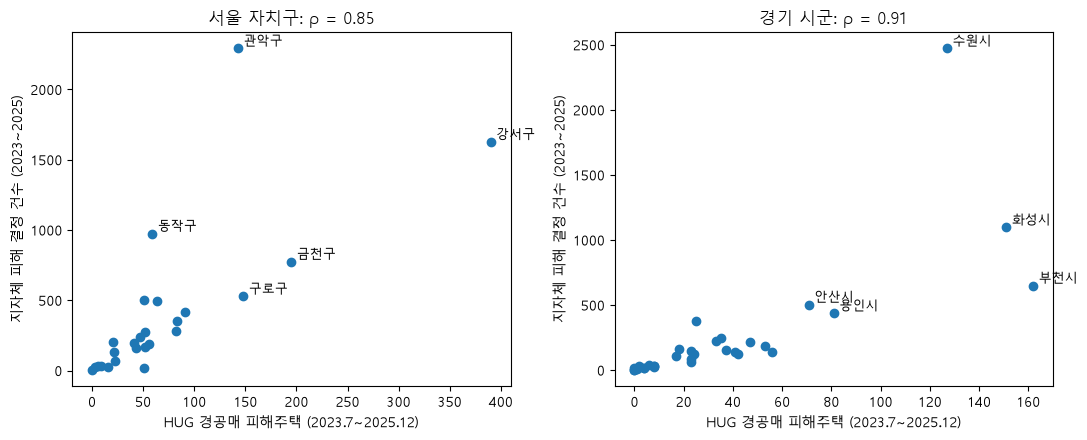

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (d, xc, yc, lab, title) in zip(axes, [
        (s, "피해주택_누적", "지자체_피해", "시군구", "서울 자치구"),
        (g.reset_index(), "피해주택_누적", "지자체_피해", "시군명", "경기 시군")]):
    ax.scatter(d[xc], d[yc])
    for _, r in d.nlargest(5, yc).iterrows():
        ax.annotate(r[lab], (r[xc], r[yc]), xytext=(4, 2), textcoords="offset points", fontsize=9)
    ax.set_xlabel("HUG 경공매 피해주택 (2023.7~2025.12)")
    ax.set_ylabel("지자체 피해 결정 건수 (2023~2025)")
    ax.set_title(f"{title}: ρ = {d[xc].corr(d[yc], method='spearman'):.2f}")
plt.tight_layout(); plt.show()

### ⑤-3 지난 학기 결과와 비교
지난 학기(건수 기준)에 서울 고위험으로 꼽은 강서·금천·구로가 이번(비율 + 보정 기준)에는 어떻게 나오는가?

In [14]:
seoul = res[res["시도"] == "서울"].copy()
seoul["건수순위(서울)"] = seoul["피해주택_누적"].rank(ascending=False, method="min").astype(int)
seoul["종합순위(서울)"] = seoul["종합점수"].rank(ascending=False, method="min").astype(int)
seoul.sort_values("종합순위(서울)")[["시군구", "피해주택_누적", "건수순위(서울)", "피해율_보정",
                                    "보증사고율_보정", "종합순위(서울)", "순위", "등급"]].round(2).reset_index(drop=True).head(12)

,시군구,피해주택_누적,건수순위(서울),피해율_보정,보증사고율_보정,종합순위(서울),순위,등급
0,강서구,390,1,17.71,59.32,1,6,고위험
1,구로구,148,3,15.58,40.79,2,21,고위험
2,중구,51,13,10.08,25.00,3,74,주의
3,금천구,195,2,19.89,13.67,4,107,주의
4,관악구,143,4,9.82,19.24,5,111,주의
5,양천구,83,6,7.87,20.75,6,117,주의
6,은평구,91,5,6.31,23.34,7,127,주의
7,도봉구,43,16,7.54,12.95,8,156,안전
8,강북구,56,10,7.80,10.50,9,158,안전
9,중랑구,82,7,6.32,14.83,10,161,안전


### ⑤-4 두 지표 비교: 과거 피해와 최근 사고는 같은 곳인가

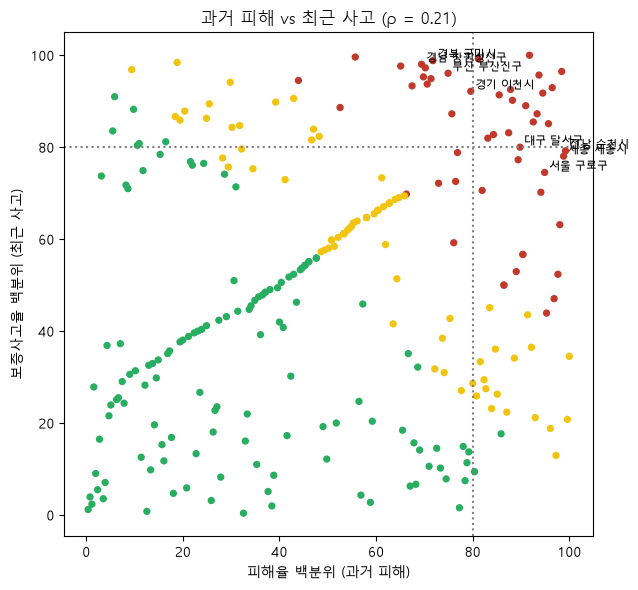

In [15]:
rho = res["피해율_보정"].corr(res["보증사고율_보정"], method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 6))
colors = res["등급"].map({"고위험": "#C0392B", "주의": "#F1C40F", "안전": "#27AE60"})
ax.scatter(res["피해율_백분위"], res["보증사고율_백분위"], c=colors, s=18)
ax.axvline(80, color="gray", ls=":"); ax.axhline(80, color="gray", ls=":")
for _, r in res[(res["피해율_백분위"] > 80) ^ (res["보증사고율_백분위"] > 80)].nlargest(8, "종합점수").iterrows():
    ax.annotate(r["이름"], (r["피해율_백분위"], r["보증사고율_백분위"]), fontsize=8, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("피해율 백분위 (과거 피해)"); ax.set_ylabel("보증사고율 백분위 (최근 사고)")
ax.set_title(f"과거 피해 vs 최근 사고 (ρ = {rho:.2f})")
plt.tight_layout(); plt.show()

**읽는 법** — 오른쪽 위(둘 다 상위 20%)는 꾸준히 위험한 곳,
**왼쪽 위**(과거 피해는 적은데 최근 사고가 많은 곳)는 **위험이 새로 커지는 지역** 후보,
오른쪽 아래는 과거 피해가 컸지만 최근 사고는 줄어든 지역이다.

## 저장

In [16]:
res.drop(columns=["이름"]).to_csv(P / "region_risk.csv", index=False, encoding="utf-8-sig")
app = res[["지역코드", "시도", "시군구", "등급", "순위", "종합점수", "피해주택_누적",
           "피해율_보정", "사고건수", "사고율", "보증사고율_보정"]].copy()
app["지역점수R"] = app["등급"].map(risk.GRADE_SCORE_R)
(BASE / "output").mkdir(exist_ok=True)
app.round(3).to_csv(BASE / "output" / "region.csv", index=False, encoding="utf-8-sig")
print("저장 완료: region_risk.csv, output/region.csv", app.shape)

저장 완료: region_risk.csv, output/region.csv (255, 12)
